# 01 - Cleaning & EDA
Zomato food delivery dataset (`saurabhbadole/zomato-delivery`). Target: `Time_taken (min)`.
Put the Kaggle CSV at `data/raw/zomato_dataset.csv` (change `RAW` if the name differs).

In [19]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns

RAW = "../data/raw/zomato_dataset.csv"
df = pd.read_csv(RAW)
df.columns = df.columns.str.strip()
print(df.shape)
df.head()

(45584, 20)


,ID,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Order_Date,Time_Orderd,Time_Order_picked,Weather_conditions,Road_traffic_density,Vehicle_condition,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,Time_taken (min)
0,0xcdcd,DEHRES17DEL01,36.0,4.2,30.327968,78.046106,30.397968,78.116106,12-02-22,21:55,22:10,Fog,Jam,2,Snack,motorcycle,3.0,No,Metropolitian,46
1,0xd987,KOCRES16DEL01,21.0,4.7,10.003064,76.307589,10.043064,76.347589,13-02-22,14:55,15:05,Stormy,High,1,Meal,motorcycle,1.0,No,Metropolitian,23
2,0x2784,PUNERES13DEL03,23.0,4.7,18.562450,73.916619,18.652450,74.006619,04-03-22,17:30,17:40,Sandstorms,Medium,1,Drinks,scooter,1.0,No,Metropolitian,21
3,0xc8b6,LUDHRES15DEL02,34.0,4.3,30.899584,75.809346,30.919584,75.829346,13-02-22,9:20,9:30,Sandstorms,Low,0,Buffet,motorcycle,0.0,No,Metropolitian,20
4,0xdb64,KNPRES14DEL02,24.0,4.7,26.463504,80.372929,26.593504,80.502929,14-02-22,19:50,20:05,Fog,Jam,1,Snack,scooter,1.0,No,Metropolitian,41


## 1. Column check against the original notebook (Gaurav Malik dataset)

In [20]:
EXPECTED = ["ID","Delivery_person_ID","Delivery_person_Age","Delivery_person_Ratings",
            "Restaurant_latitude","Restaurant_longitude","Delivery_location_latitude",
            "Delivery_location_longitude","Order_Date","Time_Orderd","Time_Order_picked",
            "Weather_conditions","Road_traffic_density","Vehicle_condition","Type_of_order",
            "Type_of_vehicle","multiple_deliveries","Festival","City","Time_taken (min)"]
print("Missing from Zomato file:", [c for c in EXPECTED if c not in df.columns])
print("New in Zomato file:     ", [c for c in df.columns if c not in EXPECTED])
print(df.dtypes)

Missing from Zomato file: []
New in Zomato file:      []
ID                                 str
Delivery_person_ID                 str
Delivery_person_Age            float64
Delivery_person_Ratings        float64
Restaurant_latitude            float64
Restaurant_longitude           float64
Delivery_location_latitude     float64
Delivery_location_longitude    float64
Order_Date                         str
Time_Orderd                        str
Time_Order_picked                  str
Weather_conditions                 str
Road_traffic_density               str
Vehicle_condition                int64
Type_of_order                      str
Type_of_vehicle                    str
multiple_deliveries            float64
Festival                           str
City                               str
Time_taken (min)                 int64
dtype: object


If anything is missing, map the Zomato names onto the expected ones here (leave `{}` if all match).

In [21]:
RENAME = {}   # e.g. {"Delivery_person_Ratings": "Delivery_person_Ratings"}
df = df.rename(columns=RENAME)

## 2. Check raw date/time formats (run before cleaning)

In [22]:
print(df["Order_Date"].astype("string").str.strip().head(5).tolist())
print(df["Time_Orderd"].astype("string").str.strip().head(5).tolist())
print("Time_Orderd share empty:", df["Time_Orderd"].isna().mean())

['12-02-22', '13-02-22', '04-03-22', '13-02-22', '14-02-22']
['21:55', '14:55', '17:30', '9:20', '19:50']
Time_Orderd share empty: 0.037973850473850476


## 3. Cleaning

In [23]:
# strip whitespace, turn "NaN " strings into real NaN
obj = df.select_dtypes(exclude="number").columns
df[obj] = df[obj].apply(lambda s: s.astype("string").str.strip())
df = df.replace({"NaN": np.nan, "nan": np.nan, "": np.nan})

# drop ID columns
df = df.drop(columns=[c for c in ["ID", "Delivery_person_ID"] if c in df.columns])

# weather: remove the "conditions" prefix
W = "Weather_conditions"   # change to the name from the column check if different
df[W] = df[W].astype("string").str.replace("conditions", "", regex=False).str.strip()

# target: remove the "(min) " prefix
df["Time_taken (min)"] = pd.to_numeric(
    df["Time_taken (min)"].astype("string").str.replace("(min)", "", regex=False).str.strip(),
    errors="coerce")

# numeric types
df["Delivery_person_Age"] = pd.to_numeric(df["Delivery_person_Age"], errors="coerce").round().astype("Int64")
df["Delivery_person_Ratings"] = pd.to_numeric(df["Delivery_person_Ratings"], errors="coerce")

# dates -> day of week, is_weekend (format is auto-detected; this file uses dd-mm-yy)
d = df["Order_Date"].astype("string").str.strip()
fmts = ["%d-%m-%y", "%d-%m-%Y", "%Y-%m-%d", "%d/%m/%Y", "%d/%m/%y", "%m/%d/%Y", "%Y/%m/%d", "%d-%b-%Y"]
rates = {f: pd.to_datetime(d, format=f, errors="coerce").notna().mean() for f in fmts}
best = max(rates, key=rates.get)
print(rates); print("using:", best)
df["Order_Date"] = pd.to_datetime(d, format=best, errors="coerce")
print("Order_Date empty share:", df["Order_Date"].isna().mean())
dow = df["Order_Date"].dt.dayofweek
df["day_of_week"] = df["Order_Date"].dt.day_name()
df["is_weekend"] = (dow >= 5).astype("Int64").where(dow.notna())

# order hour: handle both "HH:MM" text and Excel-style day fractions (0.8333 = 20:00)
t = df["Time_Orderd"].astype("string").str.strip()
h_text = pd.to_numeric(t.str.extract(r"(\d{1,2}):\d{2}")[0], errors="coerce")
frac = pd.to_numeric(t.where(~t.str.contains(":", na=False)), errors="coerce")
h_frac = np.floor(frac * 24 + 1e-6) % 24
df["order_hour"] = h_text.fillna(h_frac).astype("Int64")

print("order_hour empty share:", df["order_hour"].isna().mean())   # should be about 0.038
print(df["order_hour"].value_counts().sort_index())

{'%d-%m-%y': np.float64(1.0), '%d-%m-%Y': np.float64(0.0), '%Y-%m-%d': np.float64(0.0), '%d/%m/%Y': np.float64(0.0), '%d/%m/%y': np.float64(0.0), '%m/%d/%Y': np.float64(0.0), '%Y/%m/%d': np.float64(0.0), '%d-%b-%Y': np.float64(0.0)}
using: %d-%m-%y
Order_Date empty share: 0.0
order_hour empty share: 0.037973850473850476
order_hour
0      430
8     1817
9     1947
10    1991
11    1961
12     892
13     783
14     791
15     873
16     709
17    4277
18    4479
19    4593
20    4538
21    4685
22    4576
23    4511
Name: count, dtype: Int64


$$d = 2R \arcsin\left(\sqrt{\sin^2\left(\frac{\varphi_2 - \varphi_1}{2}\right) + \cos(\varphi_1)\cos(\varphi_2)\sin^2\left(\frac{\lambda_2 - \lambda_1}{2}\right)}\right)$$

- $\varphi_1, \varphi_2$: Latitudes of point 1 and point 2 (in radians)
- $\lambda_1, \lambda_2$: Longitudes of point 1 and point 2 (in radians)
- $\Delta\varphi = \varphi_2 - \varphi_1$: Difference in latitude
- $\Delta\lambda = \lambda_2 - \lambda_1$: Difference in longitude

In [24]:
# distance (km) between restaurant and delivery location
def haversine(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    a = np.sin((lat2-lat1)/2)**2 + np.cos(lat1)*np.cos(lat2)*np.sin((lon2-lon1)/2)**2
    return 6371 * 2 * np.arcsin(np.sqrt(a))

# some rows in this dataset family have 0/negative coordinates -> make them NaN
for c in ["Restaurant_latitude","Restaurant_longitude","Delivery_location_latitude","Delivery_location_longitude"]:
    df[c] = df[c].abs().replace(0, np.nan)
df["distance_km"] = haversine(df["Restaurant_latitude"], df["Restaurant_longitude"],
                              df["Delivery_location_latitude"], df["Delivery_location_longitude"])

In [25]:
# string categories (as in the original notebook)
for c in ["Vehicle_condition", "multiple_deliveries", "is_weekend"]:
    df[c] = pd.to_numeric(df[c], errors="coerce").astype("Int64")
CAT = ["Vehicle_condition","multiple_deliveries","is_weekend","day_of_week","Weather_conditions",
       "Road_traffic_density","Type_of_order","Type_of_vehicle","Festival","City"]
for c in CAT:
    df[c] = df[c].astype("string")

# drop rows without target + duplicates; drop raw columns no longer needed
df = df.dropna(subset=["Time_taken (min)"]).drop_duplicates()
df = df.drop(columns=["Order_Date","Time_Orderd","Time_Order_picked","Restaurant_latitude",
                      "Restaurant_longitude","Delivery_location_latitude","Delivery_location_longitude"],
             errors="ignore")
print(df.shape); print(df.isna().sum()); df.head()

(45584, 15)
Delivery_person_Age        1854
Delivery_person_Ratings    1908
Weather_conditions          616
Road_traffic_density        601
Vehicle_condition             0
Type_of_order                 0
Type_of_vehicle               0
multiple_deliveries         993
Festival                    228
City                       1200
Time_taken (min)              0
day_of_week                   0
is_weekend                    0
order_hour                 1731
distance_km                3640
dtype: int64


,Delivery_person_Age,Delivery_person_Ratings,Weather_conditions,Road_traffic_density,Vehicle_condition,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,Time_taken (min),day_of_week,is_weekend,order_hour,distance_km
0,36,4.2,Fog,Jam,2,Snack,motorcycle,3,No,Metropolitian,46,Saturday,1,21,10.280582
1,21,4.7,Stormy,High,1,Meal,motorcycle,1,No,Metropolitian,23,Sunday,1,14,6.242319
2,23,4.7,Sandstorms,Medium,1,Drinks,scooter,1,No,Metropolitian,21,Friday,0,17,13.787860
3,34,4.3,Sandstorms,Low,0,Buffet,motorcycle,0,No,Metropolitian,20,Sunday,1,9,2.930258
4,24,4.7,Fog,Jam,1,Snack,scooter,1,No,Metropolitian,41,Monday,0,19,19.396618


In [26]:
df.to_csv("../data/processed/clean.csv", index=False)

## 4. EDA  (paste your existing EDA cells from `analysis.ipynb` below this line)

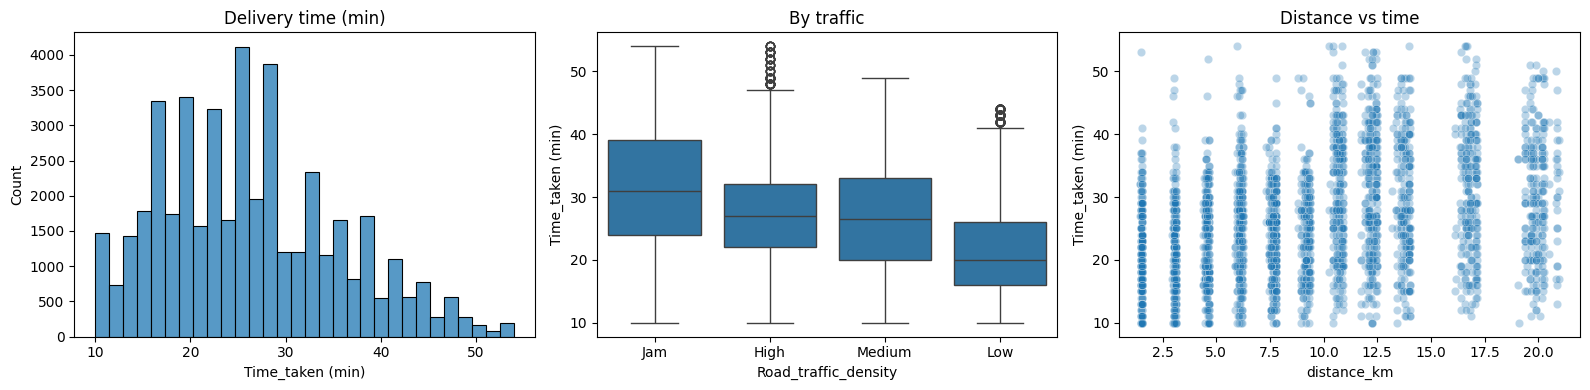

In [33]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(df["Time_taken (min)"], bins=30, ax=ax[0]); ax[0].set_title("Delivery time (min)")
sns.boxplot(data=df, x="Road_traffic_density", y="Time_taken (min)", ax=ax[1]); ax[1].set_title("By traffic")
sns.scatterplot(data=df.sample(min(len(df), 3000), random_state=42), x="distance_km",
                y="Time_taken (min)", alpha=.3, ax=ax[2]); ax[2].set_title("Distance vs time")
plt.tight_layout(); plt.savefig("../figures/eda_overview.png", dpi=150); plt.show()

In [28]:
print(df.isna().mean().mul(100).round(1).sort_values(ascending=False))
print(df.isna().sum(axis=1).value_counts().sort_index())   # how many blanks per row

distance_km                8.0
Delivery_person_Ratings    4.2
Delivery_person_Age        4.1
order_hour                 3.8
City                       2.6
multiple_deliveries        2.2
Weather_conditions         1.4
Road_traffic_density       1.3
Festival                   0.5
Vehicle_condition          0.0
Type_of_order              0.0
Type_of_vehicle            0.0
Time_taken (min)           0.0
is_weekend                 0.0
day_of_week                0.0
dtype: float64
0    38055
1     5336
2      427
3     1068
4      182
5      448
6       67
7        1
Name: count, dtype: int64


In [29]:
feat = [c for c in df.columns if c != "Time_taken (min)"]
df = df[df[feat].isna().sum(axis=1) <= 3]
print(df.shape)

(44886, 15)


In [30]:
# drop rows with 4+ blanks in the features, then save
feat = [c for c in df.columns if c != "Time_taken (min)"]
df = df[df[feat].isna().sum(axis=1) <= 3]
print(df.shape)

df.to_csv("../data/processed/clean.csv", index=False)

# quick check of the saved file
chk = pd.read_csv("../data/processed/clean.csv")
print(chk.shape)
print(chk[["day_of_week", "is_weekend"]].isna().sum())   # should be 0
print(chk["day_of_week"].value_counts())

(44886, 15)
(44886, 15)
day_of_week    0
is_weekend     0
dtype: int64
day_of_week
Wednesday    6985
Friday       6917
Tuesday      6257
Thursday     6249
Saturday     6202
Sunday       6161
Monday       6115
Name: count, dtype: int64


In [40]:
print(df["distance_km"].describe())
print((df["distance_km"] > 50).sum(), "rows over 50 km")

count    41378.000000
mean         9.720607
std          5.600585
min          1.465067
25%          4.657655
50%          9.193021
75%         13.680920
max         20.969489
Name: distance_km, dtype: float64
0 rows over 50 km
